## **1. Implementación del código fuente**
---
Esta sección contiene todo el análisis realizado, consta de dos partes:

- **Parte A** replica el artículo de Guimerà et al. (2005) con la red OpenFlights 2014.
- **Parte B** estudia el efecto de la guerra Rusia-Ucrania con un escenario contrafactual y con redes reales de OpenSky (2021-2022).

### **Parte A. Réplica de Guimerà et al. (2005) con OpenFlights**

**A.1 Datos.** Se importan las librerías y se descargan `airports.dat` y `routes.dat` del repositorio de OpenFlights. Ambos archivos son CSV sin encabezado, con `\N` como valor faltante, así que se asignan los nombres de columna manualmente.

In [1]:
import os, urllib.request, warnings
import numpy as np, pandas as pd, networkx as nx
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
mil = lambda x: f"{x:,}".replace(",", ".")
mpl.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

In [2]:
BASE = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/"
os.makedirs("data", exist_ok=True)
for f in ["airports.dat", "routes.dat"]:
    if not os.path.exists(f"data/{f}"):
        urllib.request.urlretrieve(BASE + f, f"data/{f}")

cols_ap = ['id','name','city','country','iata','icao','lat','lon','alt','tz','dst','tzdb','type','source']
cols_rt = ['airline','airline_id','src','src_id','dst','dst_id','codeshare','stops','equipment']
ap = pd.read_csv("data/airports.dat", header=None, names=cols_ap, na_values=['\\N'], keep_default_na=False)
rt = pd.read_csv("data/routes.dat",   header=None, names=cols_rt, na_values=['\\N'], keep_default_na=False)
print(f"airports.dat: {mil(len(ap))} aeropuertos | routes.dat: {mil(len(rt))} rutas de {rt.airline.nunique()} aerolíneas")

airports.dat: 7.698 aeropuertos | routes.dat: 67.663 rutas de 568 aerolíneas


**A.2 Bloques geopolíticos.** Para relacionar la red con la guerra, cada país se asigna a un bloque. El bloque "Occidente (sanciones)" agrupa a los países que entre el 26 de febrero y el 2 de marzo de 2022 cerraron su espacio aéreo a los operadores rusos o fueron vetados por Rusia (Teslova, 2022; CBC News, 2022). Los demás países se asignan por región; el continente se infiere de la zona horaria más frecuente de sus aeropuertos.

In [3]:
# A.2 Clasificación geopolítica de los países
# Bloque que cerró su espacio aéreo a Rusia (o fue vetado por ella) entre el 26-feb y el 2-mar-2022:
# los 36 países de la lista de Rosaviatsia (UE-27, Reino Unido, Canadá, Noruega, Islandia, Albania y
# territorios británicos) más Estados Unidos y Suiza, que adoptaron las mismas restricciones.
UE27 = ["Austria","Belgium","Bulgaria","Croatia","Cyprus","Czech Republic","Denmark","Estonia","Finland",
        "France","Germany","Greece","Hungary","Ireland","Italy","Latvia","Lithuania","Luxembourg","Malta",
        "Netherlands","Poland","Portugal","Romania","Slovakia","Slovenia","Spain","Sweden"]
SANCIONADORES = set(UE27 + ["United Kingdom","Canada","United States","Norway","Iceland","Switzerland",
        "Albania","Gibraltar","Jersey","Guernsey","Isle of Man","Faroe Islands","Greenland",
        "British Virgin Islands","Anguilla"])
CAUCASO_ASIA_C = {"Armenia","Georgia","Azerbaijan","Kazakhstan","Uzbekistan","Kyrgyzstan","Tajikistan","Turkmenistan"}
MEDIO_ORIENTE = {"United Arab Emirates","Qatar","Saudi Arabia","Bahrain","Kuwait","Oman","Israel","Jordan",
                 "Lebanon","Iraq","Iran","Syria","Yemen"}

continente_pais = (ap.dropna(subset=["tzdb"]).assign(c=lambda d: d.tzdb.str.split("/").str[0])
                     .groupby("country").c.agg(lambda s: s.mode()[0]))

def region(pais):
    if pais == "Russia":  return "Rusia"
    if pais == "Ukraine": return "Ucrania"
    if pais == "Belarus": return "Bielorrusia"
    if pais in SANCIONADORES:  return "Occidente (sanciones)"
    if pais in CAUCASO_ASIA_C: return "Cáucaso y Asia Central"
    if pais == "Turkey":       return "Turquía"
    if pais in MEDIO_ORIENTE:  return "Medio Oriente"
    c = continente_pais.get(pais, "")
    return {"Europe": "Resto de Europa", "Africa": "África", "America": "América Latina y Caribe",
            "Asia": "Asia", "Australia": "Oceanía", "Pacific": "Oceanía", "Indian": "Asia"}.get(c, "Otros")

**A.3 De aeropuertos a ciudades.** Guimera trabajaron con ciudades, no con aeropuertos, porque viajar entre dos aeropuertos de una misma ciudad no requiere un vuelo. Se agregan en un nodo los aeropuertos de cada ciudad y se separan las ciudades homónimas que estén a más de 100 km (fórmula de haversine). El diccionario `icao2ciudad` permite aplicar exactamente el mismo mapeo a los datos de OpenSky en la Parte B.

In [4]:
# A.3 Agregación de aeropuertos en CIUDADES (como en Guimerà et al., 2005)
#- los aeropuertos de una misma ciudad forman un único nodo (JFK, LGA y EWR -> New York);
#- ciudades homónimas de un mismo país a más de 100 km se separan (Portland, OR vs. Portland, ME).
# El mapeo se construye una sola vez y se reutiliza con OpenSky (que identifica aeropuertos por código ICAO).
def haversine(la1, lo1, la2, lo2):
    la1, lo1, la2, lo2 = map(np.radians, (la1, lo1, la2, lo2))
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2-la1)/2)**2 + np.cos(la1)*np.cos(la2)*np.sin((lo2-lo1)/2)**2))

ap = ap.dropna(subset=["id"]).copy()
ap["city_key"] = ap["city"].fillna("").str.strip() + ", " + ap["country"].fillna("").str.strip()
sin_ciudad = ap["city"].fillna("").str.strip() == ""
ap.loc[sin_ciudad, "city_key"] = ap.loc[sin_ciudad, "name"] + ", " + ap.loc[sin_ciudad, "country"].fillna("")

aero2ciudad, info_ciudad = {}, {}
for key, grp in ap.groupby("city_key"):
    centros = []
    for _, a in grp.iterrows():
        for (la, lo, lab) in centros:
            if haversine(a.lat, a.lon, la, lo) < 100:
                aero2ciudad[int(a.id)] = lab; break
        else:
            lab = key if not centros else f"{key} ({a.iata})"
            centros.append((a.lat, a.lon, lab)); aero2ciudad[int(a.id)] = lab
            info_ciudad[lab] = dict(lat=a.lat, lon=a.lon, pais=a.country, region=region(a.country))

icao2ciudad = {i: aero2ciudad[int(a)] for i, a in zip(ap.icao, ap.id) if isinstance(i, str) and len(i) == 4}
print(f"{mil(len(aero2ciudad))} aeropuertos agregados en {mil(len(info_ciudad))} ciudades; "
      f"{mil(len(icao2ciudad))} aeropuertos con código ICAO")

7.698 aeropuertos agregados en 7.278 ciudades; 7.692 aeropuertos con código ICAO


**A.4 Construcción de la red.** Cada par de ciudades con al menos un vuelo directo es una arista no dirigida y no ponderada, el mismo modelo del artículo.

In [5]:
# A.4 Red de ciudades 2014: grafo no dirigido y no ponderado (una arista = al menos un vuelo directo)
def construir_red(pares):
    """Recibe pares (ciudad_origen, ciudad_destino) y devuelve (G, componente gigante) con atributos."""
    G = nx.Graph()
    G.add_edges_from((s, t) for s, t in pares if isinstance(s, str) and isinstance(t, str) and s != t)
    nx.set_node_attributes(G, {n: info_ciudad[n] for n in G})
    H = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    return G, H

rt_d = rt.dropna(subset=["src_id", "dst_id"])
rt_d = rt_d[rt_d.stops == 0]                                   # solo vuelos sin escalas
pares14 = zip(rt_d.src_id.astype(int).map(aero2ciudad), rt_d.dst_id.astype(int).map(aero2ciudad))
G14, H14 = construir_red(pares14)
print(f"Red OpenFlights 2014: {mil(G14.number_of_nodes())} ciudades, {mil(G14.number_of_edges())} aristas, "
      f"{nx.number_connected_components(G14)} componentes")
print(f"Componente gigante: {mil(H14.number_of_nodes())} ciudades ({H14.number_of_nodes()/G14.number_of_nodes():.1%}), "
      f"{mil(H14.number_of_edges())} aristas")

Red OpenFlights 2014: 3.158 ciudades, 17.675 aristas, 3 componentes
Componente gigante: 3.152 ciudades (99.8%), 17.671 aristas


La red tiene 3.158 ciudades y 17.675 aristas. El 99,8 % de las ciudades pertenece a una misma componente, es decir, casi cualquier ciudad puede alcanzar a cualquier otra con escalas.

**A.5 Funciones de análisis.** Para garantizar que todas las redes se analicen igual, se definen tres funciones:

- `medidas_nodos`: calcula para cada ciudad el grado *k*, la intermediación *B* y su versión normalizada *b = B/⟨B⟩* (como en el artículo), la cercanía, la comunidad de Louvain (semilla 42), el grado intra-comunidad estandarizado *z*, el coeficiente de participación *P* y el rol.
- `rol`: aplica los umbrales de Guimerà y Amaral (2005). Una ciudad es hub si *z >= 2,5*, y según *P* es ultraperiférica (R1), periférica (R2), conector (R3), sin afinidad (R4), hub provincial (R5), hub conector (R6) o hub sin afinidad (R7).
- `medidas_globales`: calcula las medidas de toda la red (tamaño, densidad, componentes, distancias, agrupamiento, asortatividad y modularidad).

In [6]:
# A.5 Funciones de análisis reutilizables (se aplican igual a todas las redes del proyecto)
NOMBRES_ROL = {"R1": "ultraperiférico", "R2": "periférico", "R3": "conector no-hub", "R4": "sin afinidad no-hub",
               "R5": "hub provincial", "R6": "hub conector", "R7": "hub sin afinidad"}

def rol(z, P):
    if z < 2.5:
        return "R1" if P <= 0.05 else "R2" if P <= 0.62 else "R3" if P <= 0.80 else "R4"
    return "R5" if P <= 0.30 else "R6" if P <= 0.75 else "R7"

def medidas_nodos(H, seed=42):
    """Tabla por ciudad: grado k, intermediación B y b=B/<B>, cercanía, comunidad Louvain, z, P y rol."""
    B = nx.betweenness_centrality(H, normalized=False)
    Cc = nx.closeness_centrality(H)
    com = nx.community.louvain_communities(H, seed=seed)
    miembro = {n: i for i, c in enumerate(com) for n in c}
    filas = []
    for n in H:
        k = H.degree(n)
        kis = pd.Series([miembro[v] for v in H[n]]).value_counts()
        filas.append((n, H.nodes[n]["pais"], H.nodes[n]["region"], k, B[n], Cc[n],
                      miembro[n], kis.get(miembro[n], 0), 1 - ((kis / k) ** 2).sum()))
    T = pd.DataFrame(filas, columns=["ciudad","pais","region","k","B","cercania","comunidad","k_intra","P"])
    g = T.groupby("comunidad").k_intra
    T["z"] = ((T.k_intra - g.transform("mean")) / g.transform("std")).fillna(0)
    T["b"] = T.B / T.B.mean()
    T["rol"] = [rol(z, P) for z, P in zip(T.z, T.P)]
    return T.set_index("ciudad"), com

def medidas_globales(G, H, com):
    """Medidas globales: tamaño, densidad, conectividad, distancias, agrupamiento, asortatividad y modularidad."""
    return {"Ciudades (N)": G.number_of_nodes(), "Aristas (M)": G.number_of_edges(),
            "Grado medio <k>": round(2 * G.number_of_edges() / G.number_of_nodes(), 2),
            "Densidad": round(nx.density(G), 5),
            "Componentes conexas": nx.number_connected_components(G),
            "Ciudades en componente gigante": H.number_of_nodes(),
            "Camino mínimo promedio d": round(nx.average_shortest_path_length(H), 2),
            "Diámetro": nx.diameter(H),
            "Agrupamiento promedio C": round(nx.average_clustering(H), 3),
            "Asortatividad de grado r": round(nx.degree_assortativity_coefficient(H), 3),
            "Comunidades (Louvain)": len(com),
            "Modularidad Q": round(nx.community.modularity(H, com), 3)}

**A.6 Medidas globales y modelo nulo.** Para saber si un valor es "alto" o "bajo" hay que compararlo con una referencia. Se construyó una red aleatorizada con `double_edge_swap`, que intercambia extremos de aristas al azar 10 veces por arista y conserva el grado de cada ciudad (Maslov & Sneppen, 2002). Lo que la red real tenga de distinto respecto de esa red se debe a su organización y no a la distribución de grados.

In [7]:
# A.6 Propiedades globales de la red 2014 frente a un modelo nulo que conserva la secuencia de grados
nodos14, com14 = medidas_nodos(H14)
R14 = nx.double_edge_swap(H14.copy(), nswap=10 * H14.number_of_edges(), max_tries=100 * H14.number_of_edges(), seed=1)
R14g = R14.subgraph(max(nx.connected_components(R14), key=len))
glob14 = medidas_globales(G14, H14, com14)
def fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)): return "—"
    return f"{mil(int(v))}".replace(",", ".") if float(v).is_integer() else f"{v:g}"
tabla_A = pd.DataFrame({
    "Guimerà et al. (2005), OAG 2000": {"Ciudades (N)": 3883, "Aristas (M)": 27051,
        "Ciudades en componente gigante": 3663, "Camino mínimo promedio d": 4.4, "Agrupamiento promedio C": 0.62},
    "OpenFlights 2014": glob14}).loc[list(glob14)]
tabla_A.loc["C de la red aleatorizada"] = [0.049, round(nx.average_clustering(R14), 3)]
tabla_A.loc["d de la red aleatorizada"] = [None, round(nx.average_shortest_path_length(R14g), 2)]
tabla_A.map(fmt)

,"Guimerà et al. (2005), OAG 2000",OpenFlights 2014
Ciudades (N),3.883,3.158
Aristas (M),27.051,17.675
Grado medio <k>,—,11.19
Densidad,—,0.00355
Componentes conexas,—,3
Ciudades en componente gigante,3.663,3.152
Camino mínimo promedio d,4.4,3.88
Diámetro,—,12
Agrupamiento promedio C,0.62,0.515
Asortatividad de grado r,—,-0.056


 El camino mínimo promedio es corto (3.88 vuelos; el artículo reporta 4.4) y el agrupamiento (0.515) es unas 5 veces mayor que en la red aleatorizada (0.098). Esa combinación se considera como una red de mundo pequeño. La red es muy dispersa (densidad 0.00355), cada ciudad se conecta en promedio con 11 de las más de 3.000 existentes. La asortatividad es ligeramente negativa (−0.056), lo que indica que los hubs tienden a conectarse con ciudades pequeñas. La modularidad Q = 0.66 indica una estructura de comunidades. Las diferencias con el artículo (menos ciudades, menor C) se explican por la fuente (OpenFlights frente a OAG) y la época (2014 frente a 2000).

**A.7 Distribuciones y centralidad anómala.** Se grafican las distribuciones acumuladas *P(K ≥ k)* del grado y de la intermediación en escala log-log, como en el artículo. Luego se compara grado e intermediación de cada ciudad en la red real y en la aleatorizada. En la red aleatorizada la intermediación crece casi en línea con el grado. Las ciudades que en la red real se separan hacia arriba de esa nube tienen **centralidad anómala**: son más centrales de lo que su grado predice.

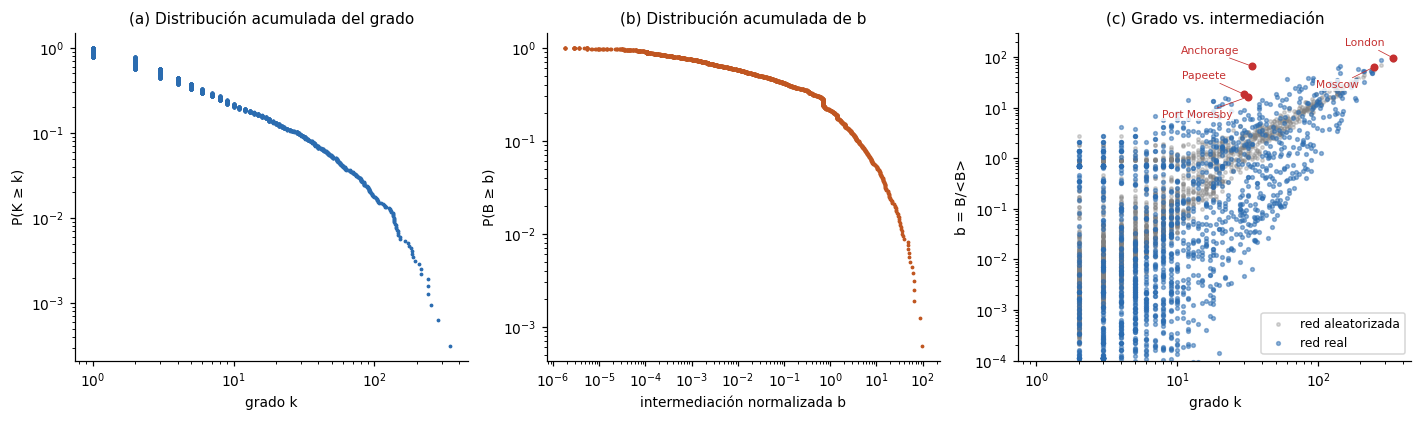

Top 10 por grado               Top 10 por intermediación               
                        ciudad    k     b                       ciudad    k     b rol
0       London, United Kingdom  344  95.0       London, United Kingdom  344  95.0  R6
1                Paris, France  282  86.3                Paris, France  282  86.3  R6
2               Moscow, Russia  252  64.3     Anchorage, United States   34  65.8  R6
3       Amsterdam, Netherlands  242  47.3   Los Angeles, United States  143  65.7  R6
4             Istanbul, Turkey  242  48.9               Moscow, Russia  252  64.3  R6
5           Frankfurt, Germany  239  51.8                 Tokyo, Japan  139  60.4  R6
6       Chicago, United States  213  51.7  Dubai, United Arab Emirates  193  57.6  R6
7       Atlanta, United States  213  32.0               Beijing, China  209  53.3  R6
8               Beijing, China  209  53.3           Frankfurt, Germany  239  51.8  R6
9  Dubai, United Arab Emirates  193  57.6       Chicago, United States  213  51.7  R5

In [8]:
# A.7 Distribuciones acumuladas y centralidad anómala (grado vs. intermediación)
Br14 = pd.Series(nx.betweenness_centrality(R14, normalized=False))
Br14 = Br14 / Br14.mean()

def ccdf(x):
    x = np.sort(np.asarray(x)); return x, 1 - np.arange(len(x)) / len(x)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
ax[0].loglog(*ccdf(nodos14.k), ".", ms=3, color="#2b6cb0")
ax[0].set(xlabel="grado k", ylabel="P(K ≥ k)", title="(a) Distribución acumulada del grado")
ax[1].loglog(*ccdf(nodos14.b[nodos14.b > 0]), ".", ms=3, color="#c05621")
ax[1].set(xlabel="intermediación normalizada b", ylabel="P(B ≥ b)", title="(b) Distribución acumulada de b")
ax[2].scatter([R14.degree(n) for n in R14], Br14[list(R14)], s=5, alpha=.3, label="red aleatorizada", color="grey")
ax[2].scatter(nodos14.k, nodos14.b, s=6, alpha=.5, label="red real", color="#2b6cb0")
ax[2].set(xscale="log", yscale="log", ylim=(1e-4, 300), xlabel="grado k", ylabel="b = B/<B>",
          title="(c) Grado vs. intermediación")
# ciudades con centralidad anómala (grado bajo, intermediación alta) y dos hubs de referencia
anomalas = {"Anchorage, United States": (-8, 8), "Port Moresby, Papua New Guinea": (-10, -14),
            "Papeete, French Polynesia": (-12, 10), "London, United Kingdom": (-6, 8), "Moscow, Russia": (-10, -14)}
for c, off in anomalas.items():
    ax[2].annotate(c.split(",")[0], (nodos14.k[c], nodos14.b[c]), xytext=off, textcoords="offset points",
                   ha="right", fontsize=7, color="#c53030", bbox=dict(fc="white", ec="none", alpha=.8, pad=.6), arrowprops=dict(arrowstyle="-", color="#c53030", lw=.5))
    ax[2].scatter(nodos14.k[c], nodos14.b[c], s=18, color="#c53030", zorder=3)
ax[2].legend(loc="lower right")
fig.tight_layout(); fig.savefig("fig1_distribuciones_centralidad.png", dpi=150); plt.show()

top_k = nodos14.nlargest(10, "k")[["k", "b"]].reset_index()
top_b = nodos14.nlargest(10, "b")[["k", "b", "rol"]].reset_index()
pd.concat({"Top 10 por grado": top_k, "Top 10 por intermediación": top_b}, axis=1).round(1)

La distribución de grado tiene cola pesada y truncada (figura 1a), hay unos pocos hubs con cientos de conexiones y miles de ciudades con muy pocas. En la figura 1c la red aleatorizada forma una banda estrecha, mientras que la red real es mucho más dispersa. Anchorage tiene solo 34 conexiones y es la tercera ciudad más intermediadora del mundo (b = 65,8), por delante de Los Ángeles y Moscú, porque une Alaska con el resto de la red. Port Moresby y Papeete cumplen el mismo papel en el Pacífico. Las tablas confirman que el top 10 por grado no coincide con el top 10 por intermediación. Moscú aparece en ambos (tercera en grado, quinta en intermediación) en 2014 era un hub global que conectaba Rusia con Europa y Asia.

**A.8 Comunidades.** Se detectan comunidades con el algoritmo de Louvain, que maximiza la modularidad, y se resume cada comunidad por su tamaño, sus bloques geopolíticos dominantes y sus hubs. El mapa ubica cada ciudad por longitud y latitud y la colorea según su comunidad.

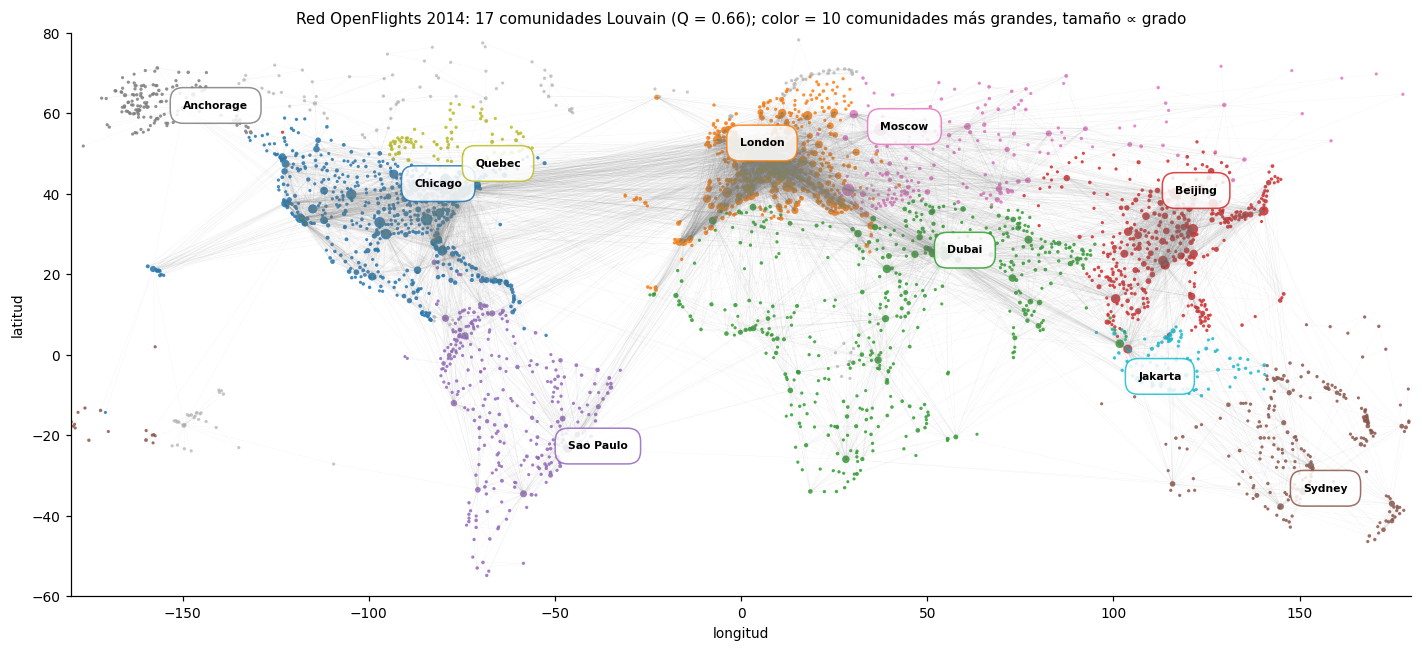

,ciudades,regiones dominantes,hubs principales
comunidad,,,
1,624,"Occidente (sanciones) (473), América Latina y ...","Chicago, Atlanta, Dallas-Fort Worth, New York"
2,480,"Occidente (sanciones) (423), África (24), Rest...","London, Paris, Amsterdam, Frankfurt"
10,471,"África (227), Asia (150), Medio Oriente (91)","Dubai, Doha, Kuala Lumpur, Jeddah"
3,386,"Asia (378), Oceanía (5), Rusia (2)","Beijing, Shanghai, Guangzhou, Tokyo"
7,300,"América Latina y Caribe (299), Otros (1)","Sao Paulo, Bogota, Panama City, Buenos Aires"
13,246,"Oceanía (244), Asia (2)","Sydney, Brisbane, Melbourne, Auckland"
11,188,"Rusia (99), Cáucaso y Asia Central (43), Turqu...","Moscow, Istanbul, St. Petersburg, Yekaterinburg"
5,131,Occidente (sanciones) (131),"Anchorage, Bethel, Fairbanks, Nome"
0,92,Occidente (sanciones) (92),"Quebec, Sioux Lookout, Thunder Bay, Wabush"


In [9]:
# A.8 Comunidades: composición geopolítica y mapa
from matplotlib.collections import LineCollection

def tabla_comunidades(T, top=10):
    """Resume cada comunidad: tamaño, regiones dominantes y sus 4 ciudades de mayor grado."""
    filas = []
    for c, g in T.groupby("comunidad"):
        reg = g.region.value_counts()
        filas.append({"comunidad": c, "ciudades": len(g),
                      "regiones dominantes": ", ".join(f"{r} ({v})" for r, v in reg.head(3).items()),
                      "hubs principales": ", ".join(g.nlargest(4, "k").index.str.split(",").str[0])})
    return pd.DataFrame(filas).sort_values("ciudades", ascending=False).head(top).set_index("comunidad")

def mapa_comunidades(H, T, ax, titulo, top=10):
    """Dibuja ciudades en coordenadas lon/lat coloreadas por comunidad (las 'top' más grandes)."""
    orden = T.comunidad.value_counts().index[:top]
    paleta = dict(zip(orden, plt.cm.tab10.colors))
    seg = [[(H.nodes[u]["lon"], H.nodes[u]["lat"]), (H.nodes[v]["lon"], H.nodes[v]["lat"])] for u, v in H.edges()
           if abs(H.nodes[u]["lon"] - H.nodes[v]["lon"]) < 180]
    ax.add_collection(LineCollection(seg, colors="grey", linewidths=.15, alpha=.15))
    col = [paleta.get(T.comunidad[n], (.75, .75, .75)) for n in H]
    ax.scatter([H.nodes[n]["lon"] for n in H], [H.nodes[n]["lat"] for n in H],
               s=[4 + T.k[n] / 4 for n in H], c=col, lw=0, alpha=.85)
    for c in orden[:top]:
        hub = T[T.comunidad == c].k.idxmax()
        ax.annotate(hub.split(",")[0], (H.nodes[hub]["lon"], H.nodes[hub]["lat"]), fontsize=7, weight="bold",
                    bbox=dict(fc="white", ec=paleta[c], alpha=.85, pad=1.2, boxstyle="round"))
    ax.set(xlim=(-180, 180), ylim=(-60, 80), xlabel="longitud", ylabel="latitud", title=titulo)

fig, ax = plt.subplots(figsize=(13, 6))
mapa_comunidades(H14, nodos14, ax, f"Red OpenFlights 2014: {len(com14)} comunidades Louvain "
                 f"(Q = {glob14['Modularidad Q']}); color = 10 comunidades más grandes, tamaño ∝ grado")
fig.tight_layout(); fig.savefig("fig2_mapa_comunidades_2014.png", dpi=150); plt.show()
tabla_comunidades(nodos14)

Las comunidades coinciden en gran parte con regiones geográficas (Norteamérica, Europa, Sudamérica, China y el este de Asia, Oceanía), pero no del todo. Una comunidad reúne Rusia, el Cáucaso, Asia Central y Turquía, con Moscú y Estambul como hubs, es una huella del espacio post-soviético y de los acuerdos bilaterales de aviación, no de la distancia. Kiev, en cambio, ya estaba en la comunidad europea de Londres y París en 2014. Así se reproduce la conclusión del artículo *la geopolítica moldea las comunidades.* Esta es la base para la Parte B.

**A.9 Roles z-P.** Cada ciudad se ubica en el plano formado por *z* (cuán conectada está dentro de su comunidad, en desviaciones estándar) y *P* (qué tan repartidas están sus conexiones entre comunidades: 0 si todas son internas, cercano a 1 si se reparten de forma uniforme). Las líneas punteadas marcan las fronteras entre los 7 roles.

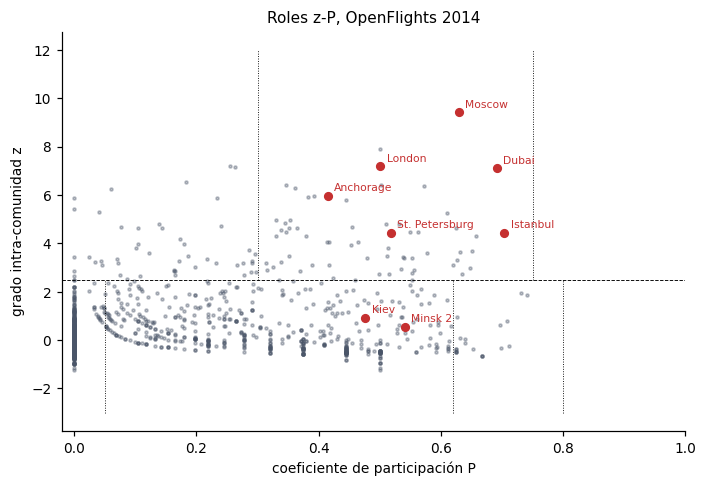

,rol,% ciudades 2014
rol,,
R1,ultraperiférico,79.9
R2,periférico,15.9
R3,conector no-hub,0.6
R4,sin afinidad no-hub,0.0
R5,hub provincial,1.5
R6,hub conector,2.0
R7,hub sin afinidad,0.0


In [10]:
# A.9 Roles de las ciudades en el plano z-P (Guimerà y Amaral, 2005)
def plano_zP(T, ax, titulo, resaltar=()):
    ax.scatter(T.P, T.z, s=4, alpha=.35, color="#4a5568")
    for x in (0.05, 0.62, 0.80): ax.plot([x, x], [-3, 2.5], "k:", lw=.6)
    for x in (0.30, 0.75):       ax.plot([x, x], [2.5, 12], "k:", lw=.6)
    ax.axhline(2.5, color="k", lw=.6, ls="--")
    for c in resaltar:
        if c in T.index:
            ax.scatter(T.P[c], T.z[c], s=25, color="#c53030", zorder=3)
            ax.annotate(c.split(",")[0], (T.P[c], T.z[c]), xytext=(4, 3), textcoords="offset points", fontsize=7,
                        color="#c53030")
    ax.set(xlabel="coeficiente de participación P", ylabel="grado intra-comunidad z", title=titulo, xlim=(-.02, 1))

CIUDADES_CLAVE = ["Moscow, Russia", "St. Petersburg, Russia", "Kiev, Ukraine", "Minsk 2, Belarus", "Istanbul, Turkey",
                  "Dubai, United Arab Emirates", "London, United Kingdom", "Anchorage, United States"]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
plano_zP(nodos14, ax, "Roles z-P, OpenFlights 2014", CIUDADES_CLAVE)
fig.tight_layout(); fig.savefig("fig3_roles_zP_2014.png", dpi=150); plt.show()

roles14 = (nodos14.rol.value_counts(normalize=True).reindex(list(NOMBRES_ROL), fill_value=0) * 100).round(1)
pd.DataFrame({"rol": [NOMBRES_ROL[r] for r in roles14.index], "% ciudades 2014": roles14.values}, index=roles14.index)

El 79,9 % de las ciudades son ultraperiféricas (R1) y el 15,9 % periféricas (R2), 95,8 % en total (95,4 % en el artículo). Solo el 3,5 % son hubs. Moscú, Londres, Dubái y Estambul son *hubs conectores* (R6) tienen muchas conexiones dentro de su comunidad y además reparten una parte importante hacia otras. Moscú es el nodo con mayor del gráfico. Kiev y Minsk son periféricas (R2). Si la guerra corta los enlaces de Moscú hacia Europa, su P debería bajar y su rol podría cambiar.

### **Parte B. Efecto de la guerra Rusia-Ucrania sobre la red**

Se usan dos diseños complementarios.
- El escenario contrafactual (B.1-B.2) aplica las restricciones de 2022 a la red 2014 y aísla el efecto puro de la guerra, porque todo lo demás queda igual.
- Las redes reales (B.3-B.11) muestran lo que efectivamente ocurrió, incluidos efectos que el escenario no contempla.

En el B.1 Escenario contrafactual. Se definen dos escenarios:
 - **E1** elimina las ciudades de Ucrania, cuyo espacio aéreo se cerró el 24 de febrero de 2022.
 - **E2** además elimina todas las aristas entre Rusia o Bielorrusia y los países de Occidente, que se vetaron mutuamente entre el 27 de febrero y el 2 de marzo. Es un ataque dirigido a nodos y aristas de una región; se recalculan todas las medidas.

In [11]:
# B.1 Escenario contrafactual: aplicar a la red 2014 las restricciones de 2022
#  E1: cierre del espacio aéreo de Ucrania (24-feb-2022) -> se eliminan las ciudades ucranianas;
#  E2: E1 + vetos cruzados Rusia/Bielorrusia <-> Occidente (27-feb a 2-mar-2022) -> se eliminan esas aristas.
def aplicar_guerra(G, cerrar_ucrania=True, vetos=True):
    G2 = G.copy()
    if cerrar_ucrania:
        G2.remove_nodes_from([n for n in G if G.nodes[n]["region"] == "Ucrania"])
    if vetos:
        bloque_ru = {"Rusia", "Bielorrusia"}
        G2.remove_edges_from([(u, v) for u, v in G2.edges()
                              if {G2.nodes[u]["region"], G2.nodes[v]["region"]} & bloque_ru
                              and "Occidente (sanciones)" in (G2.nodes[u]["region"], G2.nodes[v]["region"])])
    H2 = G2.subgraph(max(nx.connected_components(G2), key=len)).copy()
    return G2, H2

esc = {"Base 2014": (G14, H14, nodos14, com14)}
for nombre, kw in {"E1: cierre de Ucrania": dict(vetos=False), "E2: cierre + vetos": dict()}.items():
    G2, H2 = aplicar_guerra(G14, **kw)
    T2, c2 = medidas_nodos(H2)
    esc[nombre] = (G2, H2, T2, c2)

tabla_B1 = pd.DataFrame({k: medidas_globales(G, H, c) for k, (G, H, T, c) in esc.items()})
eliminadas = {k: G14.number_of_edges() - G.number_of_edges() for k, (G, H, T, c) in esc.items()}
tabla_B1.loc["Aristas eliminadas"] = list(eliminadas.values())
tabla_B1.map(fmt)

,Base 2014,E1: cierre de Ucrania,E2: cierre + vetos
Ciudades (N),3.158,3.146,3.146
Aristas (M),17.675,17.551,17.386
Grado medio <k>,11.19,11.16,11.05
Densidad,0.00355,0.00355,0.00351
Componentes conexas,3,3,6
Ciudades en componente gigante,3.152,3.140,3.137
Camino mínimo promedio d,3.88,3.88,3.9
Diámetro,12,12,12
Agrupamiento promedio C,0.515,0.515,0.514
Asortatividad de grado r,-0.056,-0.055,-0.055


Los escenarios eliminan 124 aristas (E1) y 289 aristas (E2), pero las medidas globales casi no cambian, el camino promedio pasa de 3,88 a 3,90 y el agrupamiento de 0,515 a 0,514.

La red global es robusta porque tiene muchas rutas alternativas. Las componentes pasan de 3 a 6 porque Karlovy Vary y Pardubice (República Checa) y Rimini (Italia) quedan aisladas, en 2014 solo tenían vuelos hacia Rusia, principalmente de turismo. La modularidad sube levemente de 0,66 a 0,67 porque al cortar enlaces entre bloques las comunidades quedan más separadas.

**B.2 Ciudades puente entre Rusia y Occidente.** La intermediación general mezcla todos los pares de ciudades. Para la guerra nos interesa saber ¿por qué ciudades pasan los caminos más cortos desde Rusia hacia Occidente? `betweenness_centrality_subset` cuenta solo los caminos con origen en una ciudad rusa y destino en una occidental. Se reporta la fracción de esos caminos que atraviesa cada ciudad de un tercer país y la distancia media en vuelos entre los dos bloques.

In [12]:
# B.2 ¿Quién conecta ahora a Rusia con Occidente? Intermediación restringida a pares Rusia-Occidente
# betweenness_centrality_subset cuenta, para cada ciudad, la fracción de caminos mínimos que pasan por ella
# entre una ciudad rusa (origen) y una ciudad occidental (destino). Nos interesan los "terceros países".
def puentes_rusia_occidente(H):
    rus = [n for n in H if H.nodes[n]["region"] == "Rusia"]
    occ = [n for n in H if H.nodes[n]["region"] == "Occidente (sanciones)"]
    bs = pd.Series(nx.betweenness_centrality_subset(H, rus, occ, normalized=False)) / (len(rus) * len(occ))
    dist = [l for r in rus for t, l in nx.single_source_shortest_path_length(H, r).items()
            if H.nodes[t]["region"] == "Occidente (sanciones)"]
    return bs, np.mean(dist)

bs_base, d_base = puentes_rusia_occidente(H14)
bs_e2,   d_e2   = puentes_rusia_occidente(esc["E2: cierre + vetos"][1])
print(f"Vuelos promedio entre una ciudad rusa y una occidental: {d_base:.2f} (2014) -> {d_e2:.2f} (escenario E2)")
print(f"Ciudades occidentales que solo tenían vuelos a Rusia y quedan aisladas: "
      f"{sorted(set(H14) - set(esc['E2: cierre + vetos'][1]) - {n for n in H14 if H14.nodes[n]['region']=='Ucrania'})}")

terceros = [n for n in H14 if H14.nodes[n]["region"] not in ("Rusia", "Occidente (sanciones)", "Ucrania")]
puentes = pd.DataFrame({"región": [H14.nodes[n]["region"] for n in terceros],
                        "Base 2014": bs_base[terceros], "E2": bs_e2.reindex(terceros).fillna(0)}, index=terceros)
puentes["cambio (E2 - base)"] = puentes["E2"] - puentes["Base 2014"]
puentes.sort_values("E2", ascending=False).head(10).round(3)

Vuelos promedio entre una ciudad rusa y una occidental: 3.76 (2014) -> 4.18 (escenario E2)
Ciudades occidentales que solo tenían vuelos a Rusia y quedan aisladas: ['Karlovy Vary, Czech Republic', 'Pardubice, Czech Republic', 'Rimini, Italy']


,región,Base 2014,E2,cambio (E2 - base)
"Beijing, China",Asia,0.033,0.074,0.041
"Dubai, United Arab Emirates",Medio Oriente,0.028,0.074,0.046
"Istanbul, Turkey",Turquía,0.020,0.062,0.042
"Cancun, Mexico",América Latina y Caribe,0.007,0.039,0.032
"Tokyo, Japan",Asia,0.012,0.037,0.025
"Seoul, South Korea",Asia,0.008,0.029,0.021
"Punta Cana, Dominican Republic",América Latina y Caribe,0.004,0.024,0.020
"Tel-aviv, Israel",Medio Oriente,0.003,0.020,0.016
"Antalya, Turkey",Turquía,0.002,0.014,0.012
"Bangkok, Thailand",Asia,0.003,0.011,0.008


Sin vuelos directos, un viaje promedio entre una ciudad rusa y una occidental pasa de 3,76 a 4,18 vuelos. Las ciudades que absorben los caminos son Dubái (de 0,028 a 0,074), Pekín (de 0,033 a 0,074) y Estambul (de 0,020 a 0,062), países que no se sumaron a los vetos y que tienen hubs con conexiones a ambos bloques. El modelo predice así quiénes serían los nuevos intermediarios.

**B.3 Datos reales de OpenSky.** Se descargan de Zenodo seis listas mensuales de vuelos: cuatro antes de la invasión (enero, abril y octubre de 2021 y enero de 2022) y dos después (abril de 2022, el choque inicial, y octubre de 2022, la reconfiguración). Los meses de 2021 sirven de **control estacional**: si enero a abril cambia igual en 2021 y en 2022, el cambio sería estacional y no por la guerra. Se filtran los vuelos de aerolínea por su indicativo, se mapean los aeropuertos a ciudades con `icao2ciudad` y se cuentan los vuelos por par de ciudades.

In [ ]:
# B.3 Datos reales de tráfico: OpenSky Network (Olive et al., 2023), listas mensuales en Zenodo
# Cada fila es un vuelo detectado por receptores ADS-B, con aeropuerto de origen y destino (código ICAO).
ZENODO = "https://zenodo.org/records/7923702/files/"
# Antes de la invasión: Ene-2021, Abr-2021 (control estacional), Oct-2021 y Ene-2022.
# Después: Abr-2022 (choque inicial) y Oct-2022 (reconfiguración, ocho meses después).
MESES = {"Ene-2021": "flightlist_20210101_20210131", "Abr-2021": "flightlist_20210401_20210430",
         "Oct-2021": "flightlist_20211001_20211031", "Ene-2022": "flightlist_20220101_20220131",
         "Abr-2022": "flightlist_20220401_20220430", "Oct-2022": "flightlist_20221001_20221031"}
for f in MESES.values():
    if not os.path.exists(f"data/{f}.csv.gz"):                    # ~120-200 MB cada archivo
        urllib.request.urlretrieve(ZENODO + f + ".csv.gz?download=1", f"data/{f}.csv.gz")

UMBRAL = 4   # una conexión se considera regular si tiene al menos 4 vuelos en el mes (aprox. semanal)

def red_opensky(archivo, umbral=UMBRAL):
    """Lee un mes de OpenSky y devuelve el conteo de vuelos por par de ciudades (no dirigido)."""
    v = pd.read_csv(f"data/{archivo}.csv.gz", usecols=["callsign", "origin", "destination"]).dropna()
    total = len(v)
    v = v[v.callsign.str.match(r"^[A-Z]{3}\d")]                 # vuelos de aerolínea (indicativo OACI + número)
    v["s"], v["t"] = v.origin.map(icao2ciudad), v.destination.map(icao2ciudad)
    v = v.dropna(subset=["s", "t"]).query("s != t")
    par = pd.DataFrame(np.sort(v[["s", "t"]].values, axis=1), columns=["s", "t"])
    w = par.value_counts().rename("vuelos").reset_index()
    print(f"{archivo}: {mil(total)} vuelos con origen y destino -> {mil(len(v))} comerciales entre ciudades; "
          f"{mil((w.vuelos >= umbral).sum())} pares con >= {umbral} vuelos")
    return w

W = {m: red_opensky(f) for m, f in MESES.items() if os.path.exists(f"data/{f}.csv.gz")}

flightlist_20210101_20210131: 1.077.209 vuelos con origen y destino -> 524.880 comerciales entre ciudades; 8.037 pares con >= 4 vuelos
flightlist_20210401_20210430: 1.420.412 vuelos con origen y destino -> 646.726 comerciales entre ciudades; 9.148 pares con >= 4 vuelos
flightlist_20211001_20211031: 1.734.925 vuelos con origen y destino -> 912.743 comerciales entre ciudades; 12.578 pares con >= 4 vuelos
flightlist_20220101_20220131: 1.511.894 vuelos con origen y destino -> 830.724 comerciales entre ciudades; 10.800 pares con >= 4 vuelos
flightlist_20220401_20220430: 1.868.128 vuelos con origen y destino -> 1.021.009 comerciales entre ciudades; 12.682 pares con >= 4 vuelos
flightlist_20221001_20221031: 2.123.174 vuelos con origen y destino -> 1.161.011 comerciales entre ciudades; 13.437 pares con >= 4 vuelos


**B.4 Redes mensuales.** Con el umbral de 4 vuelos por mes se construye una red por mes y se calculan sus medidas globales y locales con las mismas funciones de la Parte A. El atributo `vuelos` de cada arista guarda el número de vuelos, aunque el análisis sigue siendo no ponderado, como en el artículo.

In [ ]:
# B.4 Redes reales mensuales y sus medidas globales (cuatro meses antes y dos después de la invasión)
reales = {}
for m, w in W.items():
    w4 = w[w.vuelos >= UMBRAL]
    G, H = construir_red(zip(w4.s, w4.t))
    nx.set_edge_attributes(G, {(s, t): v for s, t, v in zip(w4.s, w4.t, w4.vuelos)}, "vuelos")
    T, c = medidas_nodos(H)
    reales[m] = (G, H, T, c)
tabla_B4 = pd.DataFrame({m: medidas_globales(G, H, c) for m, (G, H, T, c) in reales.items()})
tabla_B4.loc["Vuelos comerciales en el mes"] = [W[m].vuelos.sum() for m in reales]
tabla_B4.map(fmt)

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
Ciudades (N),1.176,1.339,1.441,1.327,1.421,1.510
Aristas (M),8.037,9.148,12.578,10.800,12.682,13.437
Grado medio <k>,13.67,13.66,17.46,16.28,17.85,17.8
Densidad,0.01163,0.01021,0.01212,0.01228,0.01257,0.01179
Componentes conexas,11,12,10,12,7,6
Ciudades en componente gigante,1.150,1.313,1.416,1.297,1.403,1.498
Camino mínimo promedio d,3.29,3.43,3.21,3.25,3.27,3.28
Diámetro,7,9,9,8,9,12
Agrupamiento promedio C,0.428,0.421,0.476,0.452,0.449,0.453
Asortatividad de grado r,-0.105,-0.085,-0.162,-0.13,-0.122,-0.127


Las redes OpenSky tienen menos ciudades que OpenFlights (de 1.176 a 1.510) porque la cobertura de receptores es parcial, pero son redes de mundo pequeño (d aprox 3,2-3,4) con comunidades marcadas (Q aprox 0,49-0,52). El número de vuelos crece durante todo el periodo por la recuperación tras la pandemia (de 524.880 a 1.161.011 vuelos al mes). Igual que en el escenario, las medidas globales casi no cambian después de la invasión, el efecto de la guerra no se ve a escala mundial sino en la región afectada, que se revisa en la sección B5.

**B.5 Vuelos de Rusia por región.** Se suman los vuelos de los pares que involucran una ciudad rusa, según la región de la otra ciudad, y aparte los vuelos con origen o destino en Ucrania.

In [ ]:
# B.5 Vuelos de Rusia por región de destino y vuelos de Ucrania (vuelos en el mes, pares con >= UMBRAL vuelos)
def vuelos_por_region(w, pais_region, umbral=UMBRAL):
    w = w[w.vuelos >= umbral].copy()
    w["rs"], w["rt"] = w.s.map(lambda n: info_ciudad[n]["region"]), w.t.map(lambda n: info_ciudad[n]["region"])
    a = w[w.rs == pais_region].assign(otra=lambda d: d.rt)
    b = w[(w.rt == pais_region) & (w.rs != pais_region)].assign(otra=lambda d: d.rs)
    x = pd.concat([a, b])
    return x.groupby("otra").vuelos.sum()

ORDEN = ["Rusia", "Occidente (sanciones)", "Turquía", "Cáucaso y Asia Central", "Medio Oriente", "Resto de Europa",
         "Bielorrusia", "Ucrania", "Asia", "África", "América Latina y Caribe"]
rus_reg = pd.DataFrame({m: vuelos_por_region(W[m], "Rusia") for m in W}).reindex(ORDEN).fillna(0).astype(int)
rus_reg.index = ["Rusia (doméstico)"] + ORDEN[1:]
ucr = pd.Series({m: int(W[m][(W[m].vuelos >= UMBRAL) & (W[m].s.map(lambda n: info_ciudad[n]["region"]).eq("Ucrania")
                 | W[m].t.map(lambda n: info_ciudad[n]["region"]).eq("Ucrania"))].vuelos.sum()) for m in W})
rus_reg.loc["— Vuelos con origen o destino en Ucrania"] = ucr
rus_reg

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
Rusia (doméstico),5532,7362,8452,6170,6082,5087
Occidente (sanciones),2078,3104,5694,5675,8,0
Turquía,906,597,1180,934,533,1094
Cáucaso y Asia Central,58,185,173,140,22,25
Medio Oriente,577,607,863,1238,654,1151
Resto de Europa,55,96,149,120,82,111
Bielorrusia,104,152,817,661,603,654
Ucrania,689,0,0,0,0,0
Asia,336,426,384,476,16,55
África,6,21,20,0,9,17


Los vuelos Rusia-Occidente pasan de 5.675 en enero de 2022 a 8 en abril y a 0 en octubre, y los vuelos de Ucrania de 4.438 a 0. El control de 2021 descarta un efecto estacional, entre enero y abril de 2021 los vuelos Rusia-Occidente aumentaron de 2.078 a 3.104.

Los vuelos Rusia-Ucrania de enero de 2021 (689) corresponden a Crimea(Simferópol y Sarabuz), que OpenFlights registra como Ucrania dejan de aparecer desde abril de 2021, de modo que no forman parte del cambio de 2022. La caída hacia Asia y el Cáucaso en abril de 2022 coincide con la suspensión de los vuelos internacionales de Aeroflot desde el 8 de marzo (FlightGlobal, 2022).

**B.6 Control de calidad de la cobertura.** Un descenso de vuelos puede deberse a que hubo menos vuelos o a que hubo menos receptores que los detectaran. Para separar ambos se mide, para las aerolíneas rusas (Aeroflot, Rossiya, S7, Pobeda, UTair y otras), qué porcentaje de sus vuelos detectados tiene origen y destino identificados.

In [ ]:
# B.6 Control de calidad: cobertura de OpenSky sobre aerolíneas rusas
# OpenSky depende de receptores voluntarios; si en Rusia se apagan receptores, se pierden orígenes/destinos.
# Medimos qué fracción de vuelos de aerolíneas rusas (por prefijo OACI del indicativo) tiene ambos extremos.
PREF_RU = ("AFL", "SDM", "SBI", "PBD", "UTA", "SVR", "AUL", "NWS", "RSY", "KAR", "UBE")
cobertura = {}
for m, f in MESES.items():
    v = pd.read_csv(f"data/{f}.csv.gz", usecols=["callsign", "origin", "destination"])
    v = v[v.callsign.fillna("").str[:3].isin(PREF_RU)]
    cobertura[m] = {"vuelos de aerolíneas rusas detectados": len(v),
                    "% con origen y destino identificados": round(100 * v[["origin", "destination"]].notna().all(axis=1).mean(), 1)}
pd.DataFrame(cobertura).map(fmt)

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
vuelos de aerolíneas rusas detectados,31.559,37.678,51.472,42.412,25.828,39.877
% con origen y destino identificados,25.4,27.5,26.2,27.3,24.1,15.5


Hasta abril de 2022 la cobertura era estable (24-27 %), así que la comparación enero a abril de 2022 no está sesgada por la cobertura. En octubre de 2022 cae al 15,5 %, de modo que los conteos absolutos dentro de Rusia de ese mes están subestimados. Por eso las conclusiones se basan en proporciones y en los enlaces con Occidente, que se observan desde receptores europeos con buena cobertura.

**B.7 Figura de la reorientación de Rusia.** El panel (a) muestra qué porcentaje de los vuelos internacionales de Rusia va a cada región. Las proporciones son menos sensibles a la cobertura que los conteos. El panel (b) muestra los enlaces que desaparecen (Rusia-Occidente y Ucrania) frente a los que resisten (Turquía y Medio Oriente).

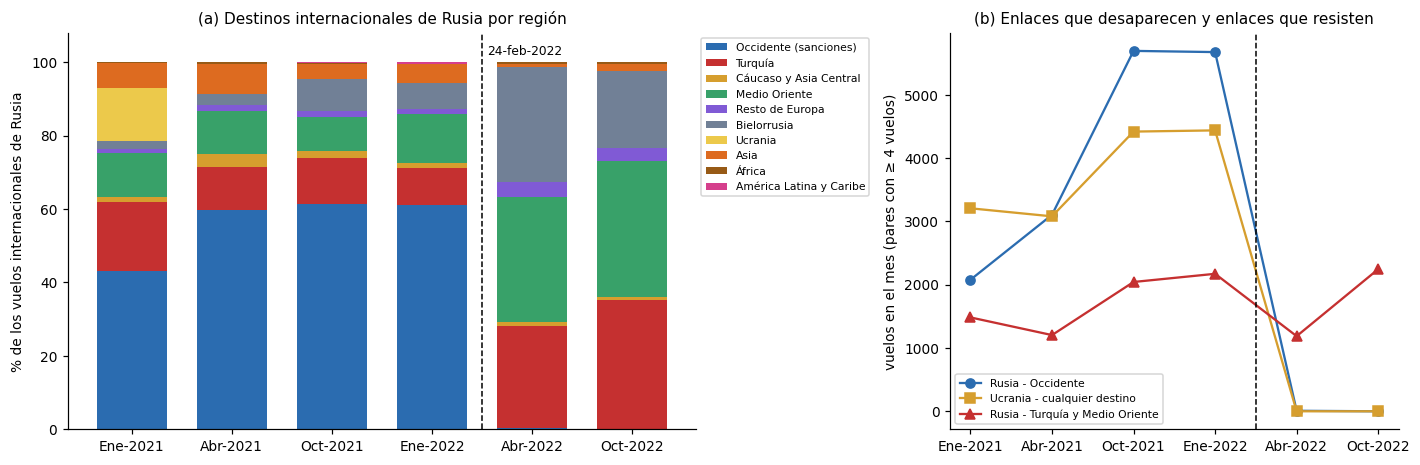

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
Occidente (sanciones),43.2,59.8,61.3,61.1,0.4,0.0
Turquía,18.8,11.5,12.7,10.1,27.7,35.2
Cáucaso y Asia Central,1.2,3.6,1.9,1.5,1.1,0.8
Medio Oriente,12.0,11.7,9.3,13.3,33.9,37.0
Resto de Europa,1.1,1.9,1.6,1.3,4.3,3.6
Bielorrusia,2.2,2.9,8.8,7.1,31.3,21.0
Ucrania,14.3,0.0,0.0,0.0,0.0,0.0
Asia,7.0,8.2,4.1,5.1,0.8,1.8
África,0.1,0.4,0.2,0.0,0.5,0.5
América Latina y Caribe,0.0,0.0,0.2,0.5,0.0,0.0


In [ ]:
# B.7 Figura: ¿hacia dónde vuela Rusia? Composición de sus vuelos internacionales y caída de Ucrania/Occidente
intl = rus_reg.drop(index=["Rusia (doméstico)", "— Vuelos con origen o destino en Ucrania"])
intl = intl.loc[intl.sum(axis=1) > 0]
cuota = 100 * intl / intl.sum()
COL_REG = {"Occidente (sanciones)": "#2b6cb0", "Turquía": "#c53030", "Cáucaso y Asia Central": "#d69e2e",
           "Medio Oriente": "#38a169", "Resto de Europa": "#805ad5", "Bielorrusia": "#718096", "Ucrania": "#ecc94b",
           "Asia": "#dd6b20", "África": "#975a16", "América Latina y Caribe": "#d53f8c", "Rusia": "#1a202c"}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
base = np.zeros(len(cuota.columns))
for r in cuota.index:
    ax[0].bar(cuota.columns, cuota.loc[r], bottom=base, color=COL_REG[r], label=r, width=.7)
    base += cuota.loc[r].values
ax[0].axvline(3.5, color="k", ls="--", lw=1); ax[0].text(3.55, 102, "24-feb-2022", fontsize=8)
ax[0].set(ylabel="% de los vuelos internacionales de Rusia", ylim=(0, 108),
          title="(a) Destinos internacionales de Rusia por región")
ax[0].legend(fontsize=7, bbox_to_anchor=(1.0, 1), loc="upper left")
ax[1].plot(rus_reg.columns, rus_reg.loc["Occidente (sanciones)"], "o-", color="#2b6cb0", label="Rusia - Occidente")
ax[1].plot(rus_reg.columns, rus_reg.loc["— Vuelos con origen o destino en Ucrania"], "s-", color="#d69e2e",
           label="Ucrania - cualquier destino")
ax[1].plot(rus_reg.columns, rus_reg.loc["Turquía"] + rus_reg.loc["Medio Oriente"], "^-", color="#c53030",
           label="Rusia - Turquía y Medio Oriente")
ax[1].axvline(3.5, color="k", ls="--", lw=1)
ax[1].set(ylabel=f"vuelos en el mes (pares con ≥ {UMBRAL} vuelos)", title="(b) Enlaces que desaparecen y enlaces que resisten")
ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig("fig4_rusia_destinos.png", dpi=150); plt.show()
cuota.round(1)

Occidente pasó de ser el destino del 61,1 % de los vuelos internacionales de Rusia (enero de 2022) al 0 % (octubre de 2022). Turquía (del 10,1 % al 35,2 %), Medio Oriente (del 13,3 % al 37,0 %) y Bielorrusia (del 7,1 % al 21,0 %) ocupan ese espacio.

En valores absolutos los vuelos hacia Turquía y Medio Oriente caen en abril por la suspensión de Aeroflot (Tabla B5). En octubre de 2022 Turquía (1.094) vuelve casi al nivel de octubre de 2021 (1.180) y Medio Oriente lo supera (1.151 frente a 863), a pesar de la menor cobertura. La red de Rusia se reorienta hacia el sur.

**B.8 Ciudades clave.** Se sigue mes a mes el grado, la intermediación normalizada, la cercanía y el rol de las ciudades directamente involucradas (Moscú, San Petersburgo, Minsk, Kiev) y de posibles intermediarias (Estambul, Dubái, Belgrado, Helsinki).


In [ ]:
# B.8 Ciudades clave mes a mes: grado k, intermediación b, cercanía y rol z-P
CLAVE = {"Moscow, Russia": "Moscú", "St. Petersburg, Russia": "San Petersburgo", "Minsk 2, Belarus": "Minsk",
         "Kiev, Ukraine": "Kiev", "Istanbul, Turkey": "Estambul", "Dubai, United Arab Emirates": "Dubái",
         "Belgrade, Serbia": "Belgrado", "Helsinki, Finland": "Helsinki"}
filas = []
for m, (G, H, T, c) in reales.items():
    for n, alias in CLAVE.items():
        r = T.loc[n] if n in T.index else None
        filas.append({"mes": m, "ciudad": alias, "k": 0 if r is None else int(r.k),
                      "b": np.nan if r is None else round(r.b, 1),
                      "cercanía": np.nan if r is None else round(r.cercania, 3), "rol": "ausente" if r is None else r.rol})
clave = pd.DataFrame(filas)
tabla_B8 = pd.concat({"grado k": clave.pivot(index="ciudad", columns="mes", values="k")[list(MESES)],
                      "intermediación b": clave.pivot(index="ciudad", columns="mes", values="b")[list(MESES)],
                      "cercanía": clave.pivot(index="ciudad", columns="mes", values="cercanía")[list(MESES)],
                      "rol z-P": clave.pivot(index="ciudad", columns="mes", values="rol")[list(MESES)]}, axis=1)
tabla_B8.loc[list(CLAVE.values())]

grado k                                              intermediación b                             ... cercanía           \
mes             Ene-2021 Abr-2021 Oct-2021 Ene-2022 Abr-2022 Oct-2022         Ene-2021 Abr-2021 Oct-2021 Ene-2022  ... Oct-2021 Ene-2022   
ciudad                                                                                                             ...                     
Moscú                 91      113      140      126       39       39             16.3     19.8     21.4     17.7  ...    0.441    0.427   
San Petersburgo       31       45       55       47       20        1              1.3      1.9      2.1      2.0  ...    0.366    0.364   
Minsk                 29       31       12        8        7        7              0.2      0.1      0.0      0.0  ...    0.332    0.325   
Kiev                  50       57       80       82        0        0              2.2      2.8      1.3      1.4  ...    0.391    0.392   
Estambul             122      136      150      138      146      159             14.6     17.8     15.6     13.0  ...    0.461    0.452   
Dubái                121      125      138      132      127      127             20.2     20.5     15.9     15.0  ...    0.457    0.450   
Belgrado              34       40       46       47       57       66              0.3      1.1      0.7      0.3  ...    0.383    0.381   
Helsinki              57       55       75       78       83       86              9.5      7.9      8.3      6.0  ...    0.418    0.419   

                                   rol z-P                                               
mes             Abr-2022 Oct-2022 Ene-2021 Abr-2021 Oct-2021 Ene-2022 Abr-2022 Oct-2022  
ciudad                                                                                   
Moscú              0.335    0.331       R6       R5       R6       R6       R2       R5  
San Petersburgo    0.324    0.248       R2       R2       R2       R2       R2       R1  
Minsk              0.321    0.318       R2       R2       R2       R2       R2       R2  
Kiev                 NaN      NaN       R2       R2       R2       R2  ausente  ausente  
Estambul           0.452    0.451       R6       R6       R2       R6       R2       R2  
Dubái              0.450    0.442       R6       R6       R6       R6       R6       R6  
Belgrado           0.385    0.386       R2       R2       R2       R2       R2       R2  
Helsinki           0.415    0.415       R2       R2       R2       R2       R2       R2  

[8 rows x 24 columns]

Kiev desaparece de la red (82 conexiones en enero de 2022, 0 desde abril). Moscú pasa de 126 a 39 conexiones, mientras que en el control de 2021 había ganado conexiones entre enero y abril (91 a 113). Su cercanía bajó de 0,427 a 0,335, en promedio queda más lejos del resto del mundo.

Su rol cambia de *hub conector* (R6) a *periférico* (R2) en abril de 2022 y a *hub provincial* (R5) en octubre, es decir, un hub cuyas conexiones quedan casi todas dentro de su propia comunidad. Moscú conserva una intermediación relativamente alta (12,5 a 13,3) con muy pocas conexiones, se vuelve el embudo por el que pasa casi todo el tráfico ruso, un caso de centralidad anómala producido por el aislamiento. Belgrado, el único gran aeropuerto europeo sin veto, gana conexiones (47 a 66).

**B.9 ¿Con quién se agrupa Moscú?** Louvain es un algoritmo estocástico, y con una sola semilla Moscú puede caer en comunidades distintas sin que la red cambie. Para obtener un resultado robusto se ejecuta Louvain 20 veces por mes (semillas 0-19) y se cuenta en qué fracción de las ejecuciones Moscú comparte comunidad con cada ciudad de referencia.

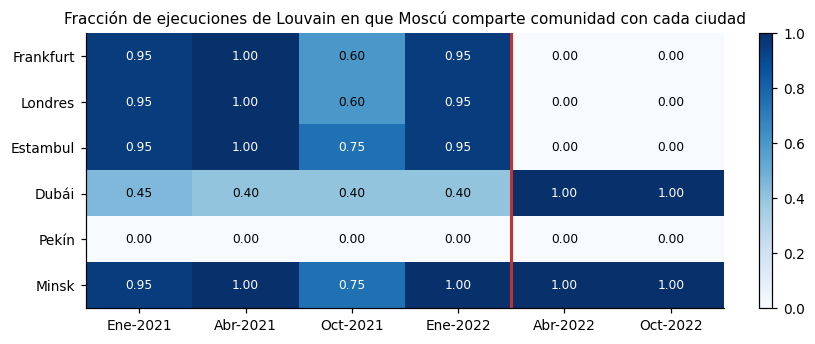

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
Frankfurt,0.95,1.0,0.60,0.95,0.0,0.0
Londres,0.95,1.0,0.60,0.95,0.0,0.0
Estambul,0.95,1.0,0.75,0.95,0.0,0.0
Dubái,0.45,0.4,0.40,0.40,1.0,1.0
Pekín,0.00,0.0,0.00,0.00,0.0,0.0
Minsk,0.95,1.0,0.75,1.00,1.0,1.0


In [ ]:
# B.9 ¿Con quién se agrupa Moscú? Co-asignación en 20 ejecuciones de Louvain (semillas 0-19)
REF = {"Frankfurt": "Frankfurt, Germany", "Londres": "London, United Kingdom", "Estambul": "Istanbul, Turkey",
       "Dubái": "Dubai, United Arab Emirates", "Pekín": "Beijing, China", "Minsk": "Minsk 2, Belarus"}
co_moscu = {}
for m, (G, H, T, c) in reales.items():
    cuenta = dict.fromkeys(REF, 0)
    for s in range(20):
        miembro = {n: i for i, cc in enumerate(nx.community.louvain_communities(H, seed=s)) for n in cc}
        for k, n in REF.items():
            cuenta[k] += miembro.get(n, -1) == miembro["Moscow, Russia"]
    co_moscu[m] = {k: v / 20 for k, v in cuenta.items()}
co_moscu = pd.DataFrame(co_moscu)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
im = ax.imshow(co_moscu.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(co_moscu.columns)), co_moscu.columns); ax.set_yticks(range(len(co_moscu)), co_moscu.index)
for i in range(co_moscu.shape[0]):
    for j in range(co_moscu.shape[1]):
        v = co_moscu.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > .6 else "black")
ax.axvline(3.5, color="#c53030", lw=2)
ax.set_title("Fracción de ejecuciones de Louvain en que Moscú comparte comunidad con cada ciudad")
fig.colorbar(im, ax=ax, fraction=.03); fig.tight_layout(); fig.savefig("fig5_comunidad_moscu.png", dpi=150); plt.show()
co_moscu.round(2)

Antes de la guerra Moscú pertenecía a la comunidad europea, compartía comunidad con Frankfurt y Londres en el 60-100 % de las ejecuciones. Después de la guerra, en el 0 %, y en el 100 % de los casos queda agrupada con Dubái y Minsk. Estambul, que compartía comunidad con Moscú, queda del lado europeo. Es la versión con datos reales de lo que describían Guimera et al. (2005), las comunidades reflejan la geopolítica, y cuando la geopolítica cambia, las comunidades cambian.

**B.10 Nuevos intermediarios en los datos reales.** Se aplicó la medida de B2 a cada red mensual para comprobar si los puentes predichos por el escenario aparecen en la realidad.

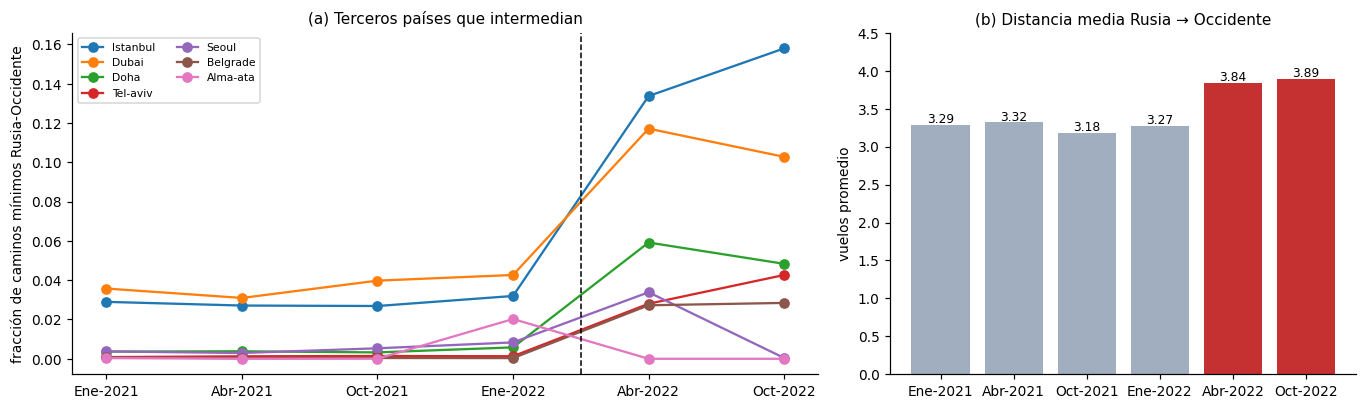

,Ene-2021,Abr-2021,Oct-2021,Ene-2022,Abr-2022,Oct-2022
"Istanbul, Turkey",0.029,0.027,0.027,0.032,0.134,0.158
"Dubai, United Arab Emirates",0.036,0.031,0.040,0.043,0.117,0.103
"Doha, Qatar",0.004,0.004,0.003,0.006,0.059,0.048
"Tel-aviv, Israel",0.001,0.001,0.001,0.001,0.028,0.043
"Seoul, South Korea",0.004,0.003,0.005,0.008,0.034,0.000
"Belgrade, Serbia",0.001,0.000,0.000,0.000,0.027,0.028
"Alma-ata, Kazakhstan",0.000,0.000,0.000,0.020,0.000,0.000


In [ ]:
# B.10 Ciudades puente entre Rusia y Occidente en los datos reales (misma medida que en B2)
puentes_real, dist_real = {}, {}
for m, (G, H, T, c) in reales.items():
    bs, d = puentes_rusia_occidente(H)
    terceros = [n for n in H if H.nodes[n]["region"] not in ("Rusia", "Occidente (sanciones)", "Ucrania")]
    puentes_real[m], dist_real[m] = bs[terceros], d
puentes_real = pd.DataFrame(puentes_real).fillna(0)
top_puentes = puentes_real[["Ene-2022", "Abr-2022", "Oct-2022"]].max(axis=1).nlargest(7).index

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for n in top_puentes:
    ax[0].plot(puentes_real.columns, puentes_real.loc[n], "o-", label=n.split(",")[0])
ax[0].axvline(3.5, color="k", ls="--", lw=1)
ax[0].set(ylabel="fracción de caminos mínimos Rusia-Occidente", title="(a) Terceros países que intermedian")
ax[0].legend(fontsize=7, ncol=2)
ax[1].bar(list(dist_real), list(dist_real.values()), color=["#a0aec0"] * 4 + ["#c53030"] * 2)
ax[1].set(ylim=(0, 4.5), ylabel="vuelos promedio", title="(b) Distancia media Rusia → Occidente")
for i, v in enumerate(dist_real.values()): ax[1].text(i, v + .03, f"{v:.2f}", ha="center", fontsize=8)
fig.tight_layout(); fig.savefig("fig6_puentes_rusia_occidente.png", dpi=150); plt.show()
puentes_real.loc[top_puentes].round(3)

La fracción de caminos mínimos Rusia-Occidente que pasan por Estambul se multiplica por cinco (de 0,032 a 0,158), por Dubái por más de dos (de 0,043 a 0,103) y por Doha por ocho (de 0,006 a 0,048). Aparecen intermediarios nuevos, Tel Aviv y Belgrado, con valores casi nulos antes de la guerra. La distancia media entre los dos bloques sube de 3,27 a 3,89 vuelos, mientras que el control de 2021 se mantiene entre 3,18 y 3,32. El escenario acertó con Estambul y Dubái, Pekín no aparece, probablemente porque en 2022 China mantenía fuertes restricciones de viaje por la pandemia y porque la cobertura de OpenSky en China es baja.

**B.11 Mapa de la red ego de Rusia.** Se dibujan solo las aristas que conectan una ciudad rusa con una ciudad de otro país, coloreadas por la región de destino, en enero y octubre de 2022.

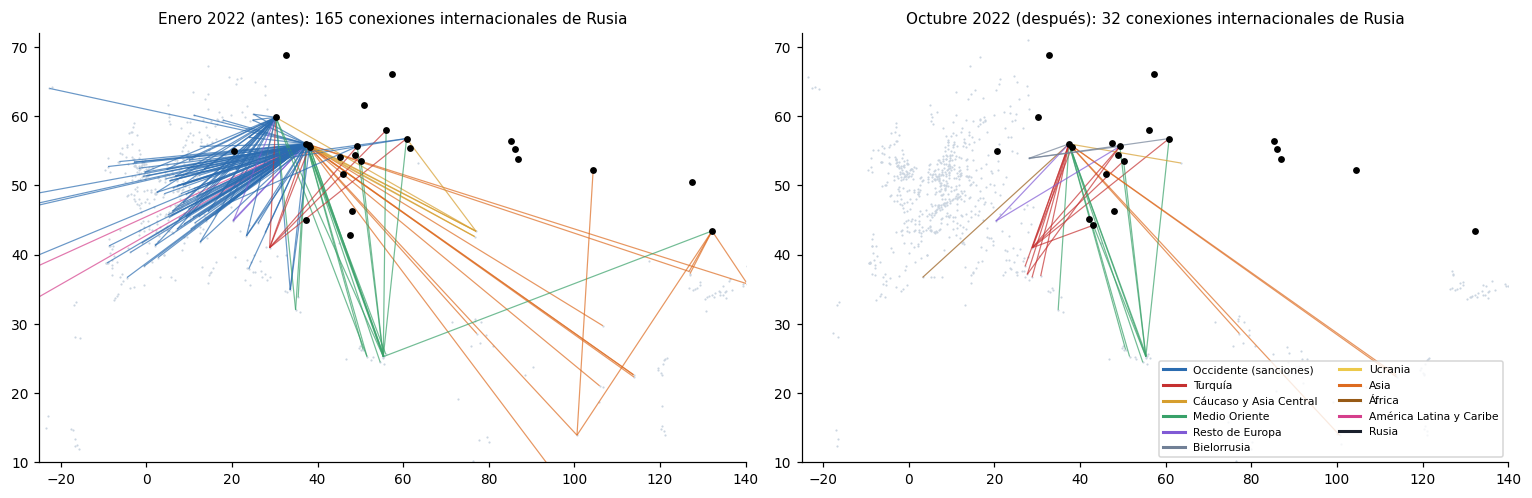

In [ ]:
# B.11 Mapa de la red ego de Rusia: aristas de ciudades rusas coloreadas por la región de destino
def mapa_ego_rusia(G, ax, titulo):
    seg, col = [], []
    for u, v in G.edges():
        ru, rv = G.nodes[u]["region"], G.nodes[v]["region"]
        if "Rusia" in (ru, rv) and not (ru == rv == "Rusia"):
            otra = rv if ru == "Rusia" else ru
            seg.append([(G.nodes[u]["lon"], G.nodes[u]["lat"]), (G.nodes[v]["lon"], G.nodes[v]["lat"])])
            col.append(COL_REG.get(otra, "grey"))
    ax.scatter([G.nodes[n]["lon"] for n in G], [G.nodes[n]["lat"] for n in G], s=2, color="#cbd5e0", lw=0)
    ax.add_collection(LineCollection(seg, colors=col, linewidths=.8, alpha=.7))
    rus = [n for n in G if G.nodes[n]["region"] == "Rusia"]
    ax.scatter([G.nodes[n]["lon"] for n in rus], [G.nodes[n]["lat"] for n in rus], s=12, color="k", zorder=3)
    ax.set(xlim=(-25, 140), ylim=(10, 72), title=f"{titulo}: {len(seg)} conexiones internacionales de Rusia")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
mapa_ego_rusia(reales["Ene-2022"][0], ax[0], "Enero 2022 (antes)")
mapa_ego_rusia(reales["Oct-2022"][0], ax[1], "Octubre 2022 (después)")
from matplotlib.lines import Line2D
ax[1].legend([Line2D([], [], color=c, lw=2) for c in COL_REG.values()], list(COL_REG), fontsize=7,
             loc="lower right", ncol=2)
fig.tight_layout(); fig.savefig("fig7_mapa_ego_rusia.png", dpi=150); plt.show()

En enero de 2022 Rusia proyectaba un abanico denso de conexiones hacia Europa occidental (azul) y hacia Asia (naranja). En octubre de 2022 el abanico europeo desaparece y lo que queda apunta hacia el sur, Turquía (rojo), el Golfo Pérsico (verde) y Bielorrusia.

**B.12 Escenario frente a realidad.** Por último se comparan, lado a lado, las predicciones del escenario contrafactual y los cambios observados.

In [ ]:
# B.12 Escenario (red 2014) frente a realidad (OpenSky Ene-2022 -> Abr-2022 y Oct-2022)
def cambio(a, b): return f"{a:g} -> {b:g} ({100 * (b - a) / a:+.0f} %)"
T_e2 = esc["E2: cierre + vetos"][2]
comparacion = pd.DataFrame({
    "Escenario E2 sobre red 2014": {
        "Grado de Moscú": cambio(nodos14.k["Moscow, Russia"], T_e2.k["Moscow, Russia"]),
        "Participación P de Moscú": f"{nodos14.P['Moscow, Russia']:.2f} -> {T_e2.P['Moscow, Russia']:.2f}",
        "Vuelos promedio Rusia -> Occidente": f"{d_base:.2f} -> {d_e2:.2f}",
        "Tres mayores puentes (terceros países)": ", ".join(puentes.E2.nlargest(3).index.str.split(",").str[0]),
        "Camino mínimo promedio de toda la red": f"{glob14['Camino mínimo promedio d']} -> {tabla_B1.loc['Camino mínimo promedio d', 'E2: cierre + vetos']}"},
    "Observado Ene-2022 -> Abr-2022": {
        "Grado de Moscú": cambio(reales["Ene-2022"][2].k["Moscow, Russia"], reales["Abr-2022"][2].k["Moscow, Russia"]),
        "Participación P de Moscú": f"{reales['Ene-2022'][2].P['Moscow, Russia']:.2f} -> {reales['Abr-2022'][2].P['Moscow, Russia']:.2f}",
        "Vuelos promedio Rusia -> Occidente": f"{dist_real['Ene-2022']:.2f} -> {dist_real['Abr-2022']:.2f}",
        "Tres mayores puentes (terceros países)": ", ".join(puentes_real["Abr-2022"].nlargest(3).index.str.split(",").str[0]),
        "Camino mínimo promedio de toda la red": f"{tabla_B4.loc['Camino mínimo promedio d', 'Ene-2022']} -> {tabla_B4.loc['Camino mínimo promedio d', 'Abr-2022']}"},
    "Observado Ene-2022 -> Oct-2022": {
        "Grado de Moscú": cambio(reales["Ene-2022"][2].k["Moscow, Russia"], reales["Oct-2022"][2].k["Moscow, Russia"]),
        "Participación P de Moscú": f"{reales['Ene-2022'][2].P['Moscow, Russia']:.2f} -> {reales['Oct-2022'][2].P['Moscow, Russia']:.2f}",
        "Vuelos promedio Rusia -> Occidente": f"{dist_real['Ene-2022']:.2f} -> {dist_real['Oct-2022']:.2f}",
        "Tres mayores puentes (terceros países)": ", ".join(puentes_real["Oct-2022"].nlargest(3).index.str.split(",").str[0]),
        "Camino mínimo promedio de toda la red": f"{tabla_B4.loc['Camino mínimo promedio d', 'Ene-2022']} -> {tabla_B4.loc['Camino mínimo promedio d', 'Oct-2022']}"}})
comparacion

,Escenario E2 sobre red 2014,Observado Ene-2022 -> Abr-2022,Observado Ene-2022 -> Oct-2022
Grado de Moscú,252 -> 169 (-33 %),126 -> 39 (-69 %),126 -> 39 (-69 %)
Participación P de Moscú,0.63 -> 0.46,0.33 -> 0.33,0.33 -> 0.29
Vuelos promedio Rusia -> Occidente,3.76 -> 4.18,3.27 -> 3.84,3.27 -> 3.89
Tres mayores puentes (terceros países),"Beijing, Dubai, Istanbul","Istanbul, Dubai, Doha","Istanbul, Dubai, Doha"
Camino mínimo promedio de toda la red,3.88 -> 3.9,3.25 -> 3.27,3.25 -> 3.28


El escenario predice correctamente la dirección de todos los cambios, Moscú pierde conexiones, aumenta la distancia entre Rusia y Occidente, Estambul y Dubái se vuelven intermediarios y la red global no cambia. Sin embargo, subestima la magnitud (−33 % frente a −69 % en el grado de Moscú) porque solo elimina los vínculos prohibidos y no los efectos en cascada: la suspensión de vuelos de Aeroflot por el riesgo de embargo de aviones arrendados, la salida de aerolíneas extranjeras y la reducción de la flota operable. La participación *P* de Moscú se mantiene porque Louvain reasigna a Moscú a una nueva comunidad (B9), *P* se mide respecto de la partición vigente, y Moscú vuelve a repartir sus enlaces entre su nueva comunidad y las vecinas.

## **2. Referencias**
---

- CBC News. (27 de febrero de 2022). Canada, European Union close airspace to Russian aircraft operators. https://www.cbc.ca/lite/story/1.6366268
- FlightGlobal. (2022). Aeroflot suspends virtually all international flights from 8 March. https://www.flightglobal.com/networks/aeroflot-suspends-virtually-all-international-flights-from-8-march/147813.article
- Guimerà, R., & Amaral, L. A. N. (2005). Functional cartography of complex metabolic networks. Nature, 433(7028), 895-900. https://doi.org/10.1038/nature03288
- Guimerà, R., Mossa, S., Turtschi, A., & Amaral, L. A. N. (2005). The worldwide air transportation network: Anomalous centrality, community structure, and cities’ global roles. Proceedings of the National Academy of Sciences, 102(22), 7794-7799. https://doi.org/10.1073/pnas.0407994102
- Maslov, S., & Sneppen, K. (2002). Specificity and stability in topology of protein networks. Science, 296(5569), 910-913. https://doi.org/10.1126/science.1065103
- Olive, X., Strohmeier, M., & Lübbe, J. (2023). Crowdsourced air traffic data from The OpenSky Network 2020 (versión v23.00) Zenodo. https://doi.org/10.5281/zenodo.7923702
- Teslova, E. (28 de febrero de 2022). Russia closes airspace to 36 countries. Anadolu Agency. https://www.aa.com.tr/en/russia-ukraine-crisis/russia-closes-airspace-to-36-countries/2518279
